In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Ekstrak zip dataset ke direktori /content/ (sesuaikan path zip di Drive kamu)
!unzip -q "/content/drive/MyDrive/DATASET_AUDIO_UAS_ML/IRMAS-TrainingData.zip" -d "/content/"

Mounted at /content/drive


In [3]:
import os
import re
import glob
import joblib
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Pastikan hasil konsisten (Reproducibility)
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Konfigurasi Dataset & Ekstraksi Fitur
DATA_DIR = "/content/IRMAS-TrainingData"  # Sesuaikan dengan path folder dataset IRMAS kamu
SR = 22050
DURATION = 3.0
TARGET_SAMPLES = int(SR * DURATION)
N_MELS = 128
N_FFT = 2048
HOP_LENGTH = 512
TARGET_FRAMES = 128
BATCH_SIZE = 32
EPOCHS = 50

print("TensorFlow version:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# Kumpulkan seluruh file .wav dan ekstrak label kelas serta group_id rekaman asalnya
records = []
classes = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])

for label in classes:
    wav_files = glob.glob(os.path.join(DATA_DIR, label, "*.wav"))
    for fp in wav_files:
        fname = os.path.basename(fp)
        # Menghapus akhiran "__<nomor potongan>.wav" agar klip dari rekaman yang sama masuk 1 grup
        group_id = re.sub(r"__\d+\.wav$", "", fname)
        records.append({
            "filepath": fp,
            "label": label,
            "group_id": group_id
        })

df = pd.DataFrame(records)
le = LabelEncoder()
df["label_idx"] = le.fit_transform(df["label"])
CLASS_NAMES = list(le.classes_)
NUM_CLASSES = len(CLASS_NAMES)

print(f"Total file audio  : {len(df)}")
print(f"Total grup lagu   : {df['group_id'].nunique()}")
print(f"Daftar kelas ({NUM_CLASSES}): {CLASS_NAMES}")

Total file audio  : 6705
Total grup lagu   : 2273
Daftar kelas (11): ['cel', 'cla', 'flu', 'gac', 'gel', 'org', 'pia', 'sax', 'tru', 'vio', 'voi']


In [5]:
# Split pertama: 80% Train+Val, 20% Test berdasarkan group_id
sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_val_idx, test_idx = next(sgkf_test.split(df, df["label_idx"], df["group_id"]))

df_train_val = df.iloc[train_val_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

# Split kedua: dari 80% tadi dibagi menjadi 75% Train (60% total) dan 25% Val (20% total)
sgkf_val = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sgkf_val.split(df_train_val, df_train_val["label_idx"], df_train_val["group_id"]))

df_train = df_train_val.iloc[train_idx].reset_index(drop=True)
df_val = df_train_val.iloc[val_idx].reset_index(drop=True)

print(f"Train set : {len(df_train)} sampel")
print(f"Val set   : {len(df_val)} sampel")
print(f"Test set  : {len(df_test)} sampel")

Train set : 4031 sampel
Val set   : 1334 sampel
Test set  : 1340 sampel


In [6]:
# Cek apakah ada kebocoran data
g_train, g_val, g_test = set(df_train["group_id"]), set(df_val["group_id"]), set(df_test["group_id"])
print("Irisan train-val :", len(g_train & g_val))
print("Irisan train-test:", len(g_train & g_test))
print("Irisan val-test  :", len(g_val & g_test))
assert not (g_train & g_val) and not (g_train & g_test) and not (g_val & g_test), "Masih ada kebocoran grup!"

Irisan train-val : 0
Irisan train-test: 0
Irisan val-test  : 0


In [7]:
def extract_3ch_spectrogram(file_path):
    # 1. Load & samakan panjang sinyal menjadi tepat 3 detik
    y, _ = librosa.load(file_path, sr=SR, duration=DURATION)
    if len(y) < TARGET_SAMPLES:
        y = np.pad(y, (0, TARGET_SAMPLES - len(y)))
    else:
        y = y[:TARGET_SAMPLES]

    # 2. Pisahkan komponen Harmonik (vokal/melodi) dan Perkusif (drum/simbal)
    y_harm, y_perc = librosa.effects.hpss(y)

    # 3. Ubah ke Mel-Spectrogram lalu skala desibel (dB)
    mel_harm = librosa.feature.melspectrogram(
        y=y_harm, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS
    )
    mel_perc = librosa.feature.melspectrogram(
        y=y_perc, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS
    )

    log_harm = librosa.power_to_db(mel_harm, ref=np.max)
    log_perc = librosa.power_to_db(mel_perc, ref=np.max)

    # 4. Hitung fitur Delta (dinamika perubahan nada/vibrato) dari komponen harmonik
    delta_harm = librosa.feature.delta(log_harm)

    # 5. Pastikan dimensi waktu tepat TARGET_FRAMES (128)
    def fix_frames(spec):
        if spec.shape[1] < TARGET_FRAMES:
            return np.pad(spec, ((0, 0), (0, TARGET_FRAMES - spec.shape[1])), mode="edge")
        return spec[:, :TARGET_FRAMES]

    log_harm = fix_frames(log_harm)
    log_perc = fix_frames(log_perc)
    delta_harm = fix_frames(delta_harm)

    # 6. Susun menjadi 3 channel (128, 128, 3) dengan skala [0, 255]
    stacked = np.stack([log_harm, log_perc, delta_harm], axis=-1)
    for c in range(3):
        c_min, c_max = stacked[:, :, c].min(), stacked[:, :, c].max()
        if c_max - c_min > 1e-6:
            stacked[:, :, c] = (stacked[:, :, c] - c_min) / (c_max - c_min) * 255.0
        else:
            stacked[:, :, c] = 0.0

    return stacked.astype(np.float32)

In [8]:
def process_dataset(dataframe, desc=""):
    X_list = []
    total = len(dataframe)
    for i, fp in enumerate(dataframe["filepath"]):
        X_list.append(extract_3ch_spectrogram(fp))
        if (i + 1) % 500 == 0 or (i + 1) == total:
            print(f"[{desc}] Memproses {i + 1}/{total} file...")
    return np.array(X_list, dtype=np.float32)

X_train = process_dataset(df_train, "TRAIN")
X_val   = process_dataset(df_val, "VAL")
X_test  = process_dataset(df_test, "TEST")

y_train = df_train["label_idx"].values
y_val   = df_val["label_idx"].values
y_test  = df_test["label_idx"].values

# Ubah label menjadi One-Hot Encoding untuk mendukung Label Smoothing
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=NUM_CLASSES)
y_val_oh   = tf.keras.utils.to_categorical(y_val, num_classes=NUM_CLASSES)
y_test_oh  = tf.keras.utils.to_categorical(y_test, num_classes=NUM_CLASSES)

# Simpan konfigurasi preprocessing untuk keperluan inferensi nanti
prep_config = {
    "sr": SR,
    "duration": DURATION,
    "target_samples": TARGET_SAMPLES,
    "n_mels": N_MELS,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "target_frames": TARGET_FRAMES,
    "class_names": CLASS_NAMES
}
joblib.dump(prep_config, "cnn_hpss_preprocessing.joblib")
print("Selesai! Shape X_train:", X_train.shape)

[TRAIN] Memproses 500/4031 file...
[TRAIN] Memproses 1000/4031 file...
[TRAIN] Memproses 1500/4031 file...
[TRAIN] Memproses 2000/4031 file...
[TRAIN] Memproses 2500/4031 file...
[TRAIN] Memproses 3000/4031 file...
[TRAIN] Memproses 3500/4031 file...
[TRAIN] Memproses 4000/4031 file...
[TRAIN] Memproses 4031/4031 file...
[VAL] Memproses 500/1334 file...
[VAL] Memproses 1000/1334 file...
[VAL] Memproses 1334/1334 file...
[TEST] Memproses 500/1340 file...
[TEST] Memproses 1000/1340 file...
[TEST] Memproses 1340/1340 file...
Selesai! Shape X_train: (4031, 128, 128, 3)


In [9]:
save_dir = "/content/drive/MyDrive/DATASET_AUDIO_UAS_ML/backup_fitur"
os.makedirs(save_dir, exist_ok=True)
np.save(f"{save_dir}/X_train.npy", X_train)
np.save(f"{save_dir}/X_val.npy", X_val)
np.save(f"{save_dir}/X_test.npy", X_test)
np.save(f"{save_dir}/y_train.npy", y_train)
np.save(f"{save_dir}/y_val.npy", y_val)
np.save(f"{save_dir}/y_test.npy", y_test)
joblib.dump(prep_config, f"{save_dir}/cnn_hpss_preprocessing.joblib")
print("Backup selesai!")

Backup selesai!


In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
class SpecAugment(layers.Layer):
    def __init__(self, freq_mask_param=16, time_mask_param=16, **kwargs):
        super().__init__(**kwargs)
        self.freq_mask_param = freq_mask_param
        self.time_mask_param = time_mask_param

    def call(self, inputs, training=None):
        if not training:
            return inputs

        freq_max = inputs.shape[1]
        time_max = inputs.shape[2]

        # Frequency Masking (XLA-compatible)
        f = tf.random.uniform([], 0, self.freq_mask_param, dtype=tf.int32)
        f0 = tf.random.uniform([], 0, freq_max - f, dtype=tf.int32)
        freq_indices = tf.range(freq_max)[None, :, None, None]
        freq_mask = tf.cast((freq_indices < f0) | (freq_indices >= f0 + f), inputs.dtype)

        # Time Masking (XLA-compatible)
        t = tf.random.uniform([], 0, self.time_mask_param, dtype=tf.int32)
        t0 = tf.random.uniform([], 0, time_max - t, dtype=tf.int32)
        time_indices = tf.range(time_max)[None, None, :, None]
        time_mask = tf.cast((time_indices < t0) | (time_indices >= t0 + t), inputs.dtype)

        return inputs * freq_mask * time_mask

    def get_config(self):
        config = super().get_config()
        config.update({"freq_mask_param": self.freq_mask_param,
                       "time_mask_param": self.time_mask_param})
        return config

In [11]:
# Hitung class weight untuk menangani ketidakseimbangan jumlah data per instrumen
weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(weights))

In [12]:
def build_model(num_classes=NUM_CLASSES):
    inputs = layers.Input(shape=(N_MELS, TARGET_FRAMES, 3))

    # Augmentasi aktif hanya saat training
    x = SpecAugment(freq_mask_param=16, time_mask_param=16)(inputs)
    x = preprocess_input(x)

    # Backbone Pre-trained EfficientNetB0
    base_model = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_tensor=x
    )

    # Buka 40 layer terakhir untuk fine-tuning fitur spektrogram
    for layer in base_model.layers[:-40]:
        layer.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=["accuracy"]
    )
    return model

model = build_model()
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spec_augment        │ (None, 128, 128,  │          0 │ input_layer[0][0] │
│ (SpecAugment)       │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ spec_augment[0][… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 128, 128,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 128, 128,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 129, 129,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 64, 64,    │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 64, 64,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 64, 64,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 64, 64,    │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 64, 64,    │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 64, 64,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 64, 64,    │          0 │ block1a_activati

 Total params: 4,385,454 (16.73 MB)

 Trainable params: 2,384,027 (9.09 MB)

 Non-trainable params: 2,001,427 (7.63 MB)

In [13]:
cb_list = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        "best_irmas_hpss_efficientnet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=cb_list,
    verbose=1
)

Epoch 1/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - accuracy: 0.1416 - loss: 3.3978
Epoch 1: val_loss improved from None to 2.07087, saving model to best_irmas_hpss_efficientnet.keras

Epoch 1: finished saving model to best_irmas_hpss_efficientnet.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 147s 645ms/step - accuracy: 0.1985 - loss: 3.0295 - val_accuracy: 0.3531 - val_loss: 2.0709 - learning_rate: 3.0000e-04
Epoch 2/50
124/126 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.2848 - loss: 2.6189
Epoch 2: val_loss did not improve from 2.07087
126/126 ━━━━━━━━━━━━━━━━━━━━ 13s 25ms/step - accuracy: 0.3014 - loss: 2.5494 - val_accuracy: 0.3853 - val_loss: 2.0779 - learning_rate: 3.0000e-04
Epoch 3/50
124/126 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.3323 - loss: 2.4146
Epoch 3: val_loss improved from 2.07087 to 1.99579, saving model to best_irmas_hpss_efficientnet.keras

Epoch 3: finished saving model to best_irmas_hpss_efficientnet.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy

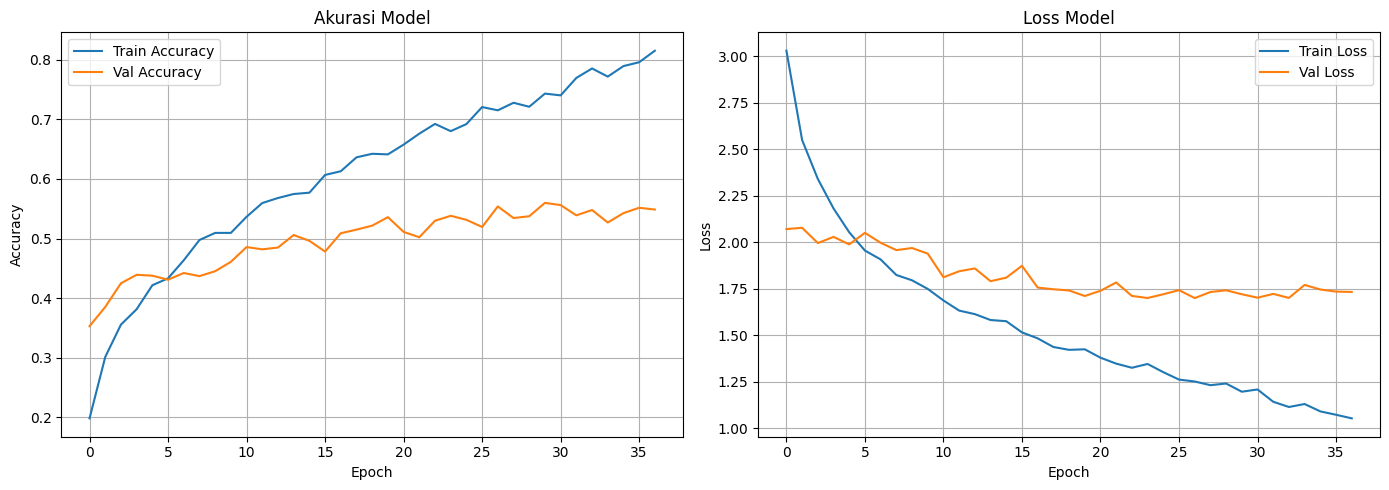

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("Akurasi Model")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Val Loss")
axes[1].set_title("Loss Model")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

42/42 ━━━━━━━━━━━━━━━━━━━━ 34s 660ms/step
Test Accuracy : 54.48%
Macro F1-Score: 0.5277

Classification Report:
              precision    recall  f1-score   support

         cel     0.5926    0.4444    0.5079        72
         cla     0.3315    0.5842    0.4229       101
         flu     0.5169    0.5412    0.5287        85
         gac     0.5327    0.8092    0.6424       131
         gel     0.4958    0.4069    0.4470       145
         org     0.8289    0.4773    0.6058       132
         pia     0.7040    0.5986    0.6471       147
         sax     0.4615    0.1714    0.2500       140
         tru     0.5448    0.6320    0.5852       125
         vio     0.3259    0.4151    0.3651       106
         voi     0.7738    0.8333    0.8025       156

    accuracy                         0.5448      1340
   macro avg     0.5553    0.5376    0.5277      1340
weighted avg     0.5691    0.5448    0.5375      1340



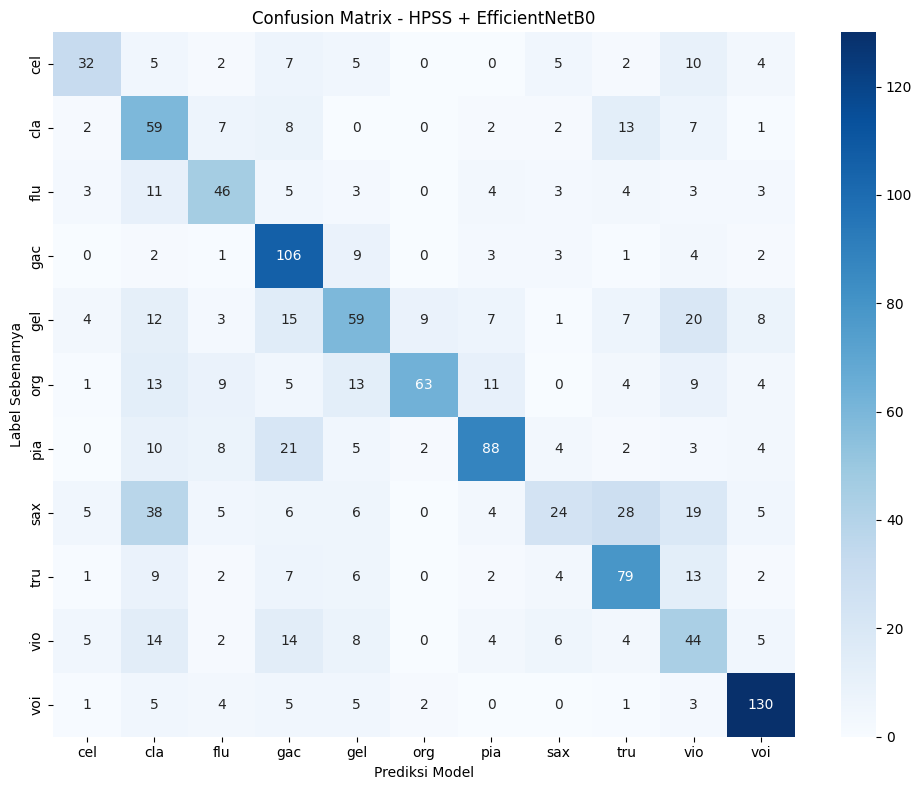

In [15]:
# Evaluasi CNN v1 di data test
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Test Accuracy : {acc * 100:.2f}%")
print(f"Macro F1-Score: {macro_f1:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix - HPSS + EfficientNetB0")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Sebenarnya")
plt.tight_layout()
plt.show()

In [16]:
IMG_SIZE = 224

def build_model_v2(num_classes=NUM_CLASSES):
    inputs = layers.Input(shape=(N_MELS, TARGET_FRAMES, 3))
    x = SpecAugment(freq_mask_param=16, time_mask_param=16)(inputs)
    x = layers.Resizing(IMG_SIZE, IMG_SIZE)(x)
    x = preprocess_input(x)

    base_model = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base_model.trainable = False
    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return models.Model(inputs, outputs), base_model

model2, base_model2 = build_model_v2()

def compile_model(m, lr):
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=["accuracy"]
    )

In [17]:
# Tahap 1: latih head saja

compile_model(model2, 1e-3)

cb_stage1 = [
    callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

hist1 = model2.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=15,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=cb_stage1,
    verbose=1
)

Epoch 1/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 113s 563ms/step - accuracy: 0.2783 - loss: 2.6155 - val_accuracy: 0.3643 - val_loss: 2.1025 - learning_rate: 0.0010
Epoch 2/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.3677 - loss: 2.2180 - val_accuracy: 0.3486 - val_loss: 2.0579 - learning_rate: 0.0010
Epoch 3/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.4165 - loss: 2.0347 - val_accuracy: 0.4010 - val_loss: 1.9850 - learning_rate: 0.0010
Epoch 4/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.4396 - loss: 1.9417 - val_accuracy: 0.4303 - val_loss: 1.9169 - learning_rate: 0.0010
Epoch 5/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 0.4426 - loss: 1.8819 - val_accuracy: 0.4588 - val_loss: 1.9109 - learning_rate: 0.0010
Epoch 6/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.4699 - loss: 1.8234 - val_accuracy: 0.4453 - val_loss: 2.0062 - learning_rate: 0.0010
Epoch 7/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.4825 - loss:

In [18]:
# Tahap 2: fine-tuning

UNFREEZE_LAST = 100

base_model2.trainable = True
cut = 0 if UNFREEZE_LAST is None else max(0, len(base_model2.layers) - UNFREEZE_LAST)
for i, layer in enumerate(base_model2.layers):
    layer.trainable = not (i < cut or isinstance(layer, layers.BatchNormalization))

compile_model(model2, 1e-5)

cb_stage2 = [
    callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
]

hist2 = model2.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=40,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=cb_stage2,
    verbose=1
)

model2.save("best_irmas_hpss_efficientnet_v2.keras")

Epoch 1/40
126/126 ━━━━━━━━━━━━━━━━━━━━ 93s 404ms/step - accuracy: 0.5698 - loss: 1.5943 - val_accuracy: 0.4948 - val_loss: 1.8645 - learning_rate: 1.0000e-05
Epoch 2/40
126/126 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.5807 - loss: 1.5680 - val_accuracy: 0.5082 - val_loss: 1.8382 - learning_rate: 1.0000e-05
Epoch 3/40
126/126 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.5867 - loss: 1.5599 - val_accuracy: 0.5142 - val_loss: 1.8300 - learning_rate: 1.0000e-05
Epoch 4/40
126/126 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.6006 - loss: 1.5484 - val_accuracy: 0.5172 - val_loss: 1.8134 - learning_rate: 1.0000e-05
Epoch 5/40
126/126 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - accuracy: 0.6105 - loss: 1.5223 - val_accuracy: 0.5120 - val_loss: 1.8123 - learning_rate: 1.0000e-05
Epoch 6/40
126/126 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.6068 - loss: 1.5019 - val_accuracy: 0.5270 - val_loss: 1.7738 - learning_rate: 1.0000e-05
Epoch 7/40
126/126 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - a

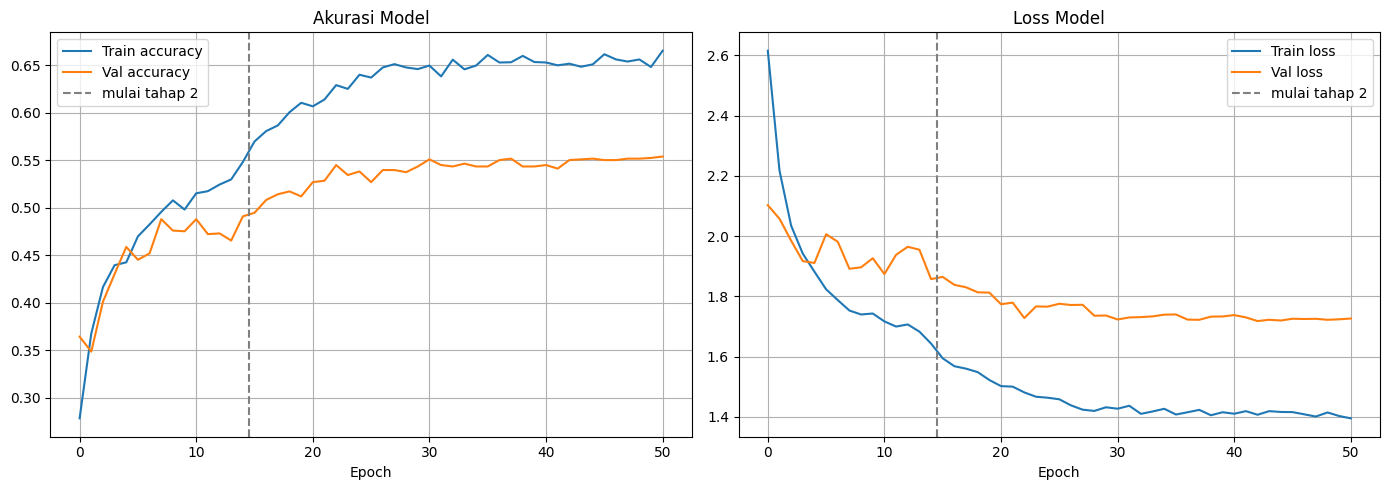

In [19]:
def cat(key): return hist1.history[key] + hist2.history[key]
n1 = len(hist1.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (k, title) in zip(axes, [("accuracy", "Akurasi Model"), ("loss", "Loss Model")]):
    ax.plot(cat(k), label=f"Train {k}")
    ax.plot(cat("val_" + k), label=f"Val {k}")
    ax.axvline(n1 - 0.5, color="gray", linestyle="--", label="mulai tahap 2")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

In [20]:
# Perbandingan v1 vs v2 di data validasi
def eval_split(m, X, y, name):
    p = np.argmax(m.predict(X, verbose=0), axis=1)
    print(f"{name:<12} acc={accuracy_score(y, p):.4f}  macro-F1={f1_score(y, p, average='macro'):.4f}")
    return p

eval_split(model,  X_val, y_val, "v1 (lama)")
_ = eval_split(model2, X_val, y_val, "v2 (baru)")

v1 (lama)    acc=0.5540  macro-F1=0.5324
v2 (baru)    acc=0.5502  macro-F1=0.5204


In [21]:
# Evaluasi CNN v2 di data test
y_pred_probs2 = model2.predict(X_test)
y_pred2 = np.argmax(y_pred_probs2, axis=1)

print(f"Test Accuracy : {accuracy_score(y_test, y_pred2) * 100:.2f}%")
print(f"Macro F1-Score: {f1_score(y_test, y_pred2, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred2, target_names=CLASS_NAMES, digits=4))

42/42 ━━━━━━━━━━━━━━━━━━━━ 24s 589ms/step
Test Accuracy : 53.36%
Macro F1-Score: 0.5076

              precision    recall  f1-score   support

         cel     0.5676    0.5833    0.5753        72
         cla     0.4640    0.5743    0.5133       101
         flu     0.5072    0.4118    0.4545        85
         gac     0.5844    0.6870    0.6316       131
         gel     0.4153    0.5241    0.4634       145
         org     0.9500    0.1439    0.2500       132
         pia     0.5146    0.7211    0.6006       147
         sax     0.5000    0.2571    0.3396       140
         tru     0.4341    0.6320    0.5147       125
         vio     0.4878    0.3774    0.4255       106
         voi     0.7746    0.8590    0.8146       156

    accuracy                         0.5336      1340
   macro avg     0.5636    0.5246    0.5076      1340
weighted avg     0.5712    0.5336    0.5128      1340



In [24]:
import librosa
from joblib import Parallel, delayed
from features import seg_features, SR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

def feat(fp):
    y, _ = librosa.load(fp, sr=SR, duration=3.0)
    return seg_features(y)

def feats(df):
    return np.array(Parallel(n_jobs=-1)(delayed(feat)(p) for p in df["filepath"]))

F_train, F_val, F_test = feats(df_train), feats(df_val), feats(df_test)

In [25]:
# ganti k / C / gamma dengan parameter terbaik di laporanmu
svm = CalibratedClassifierCV(
    make_pipeline(SelectKBest(f_classif, k=120), StandardScaler(),
                  SVC(kernel="rbf", C=100, gamma="scale")),
    cv=5, ensemble=False)
svm.fit(F_train, y_train)
p_svm_val, p_svm_test = svm.predict_proba(F_val), svm.predict_proba(F_test)

In [26]:
p_cnn_val = model2.predict(X_val, verbose=0)
p_cnn_test = y_pred_probs2

# pilih bobot di validasi, bukan di test
best_w, best_f1 = 0.5, -1
for w in np.arange(0, 1.01, 0.1):
    f = f1_score(y_val, (w*p_cnn_val + (1-w)*p_svm_val).argmax(1), average="macro")
    if f > best_f1: best_w, best_f1 = w, f

p_ens = best_w*p_cnn_test + (1-best_w)*p_svm_test
for nama, p in [("SVM", p_svm_test), ("CNN v2", p_cnn_test), (f"Ensemble w_cnn={best_w:.1f}", p_ens)]:
    pr = p.argmax(1)
    print(f"{nama:<22} acc={accuracy_score(y_test, pr):.4f}  macro-F1={f1_score(y_test, pr, average='macro'):.4f}")

SVM                    acc=0.5731  macro-F1=0.5637
CNN v2                 acc=0.5336  macro-F1=0.5076
Ensemble w_cnn=0.5     acc=0.6239  macro-F1=0.6124


In [27]:
# untuk melihat seberapa saling melengkapi CNN dan SVM?
pc, ps = p_cnn_test.argmax(1), p_svm_test.argmax(1)
print("oracle (salah satu benar):", ((pc == y_test) | (ps == y_test)).mean().round(4))
print("keduanya benar          :", ((pc == y_test) & (ps == y_test)).mean().round(4))
print("F1 ensemble di validasi :", round(best_f1, 4))

for w in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pr = (w*p_cnn_test + (1-w)*p_svm_test).argmax(1)
    print(f"w_cnn={w}: acc={accuracy_score(y_test, pr):.4f}")

print(classification_report(y_test, p_ens.argmax(1), target_names=CLASS_NAMES, digits=4))

oracle (salah satu benar): 0.7179
keduanya benar          : 0.3888
F1 ensemble di validasi : 0.5926
w_cnn=0.3: acc=0.5955
w_cnn=0.4: acc=0.6134
w_cnn=0.5: acc=0.6239
w_cnn=0.6: acc=0.6261
w_cnn=0.7: acc=0.5955
              precision    recall  f1-score   support

         cel     0.7143    0.6944    0.7042        72
         cla     0.6117    0.6238    0.6176       101
         flu     0.6491    0.4353    0.5211        85
         gac     0.5977    0.7939    0.6820       131
         gel     0.5337    0.6000    0.5649       145
         org     0.6602    0.5152    0.5787       132
         pia     0.6229    0.7415    0.6770       147
         sax     0.6265    0.3714    0.4664       140
         tru     0.5971    0.6640    0.6288       125
         vio     0.5618    0.4717    0.5128       106
         voi     0.7228    0.8526    0.7824       156

    accuracy                         0.6239      1340
   macro avg     0.6271    0.6149    0.6124      1340
weighted avg     0.6250    0.623

In [28]:
# Supaya ensemble bisa dipakai di app.py tanpa training ulang.
joblib.dump({"model": svm, "best_name": "SVM (RBF, kalibrasi)", "classes": CLASS_NAMES,
             "class_names": CLASS_NAMES, "segment_sec": DURATION},
            "svm_calibrated.joblib")
joblib.dump({"w_cnn": float(best_w), "class_names": CLASS_NAMES}, "ensemble_config.joblib")
print("Tersimpan: svm_calibrated.joblib, ensemble_config.joblib")

Tersimpan: svm_calibrated.joblib, ensemble_config.joblib


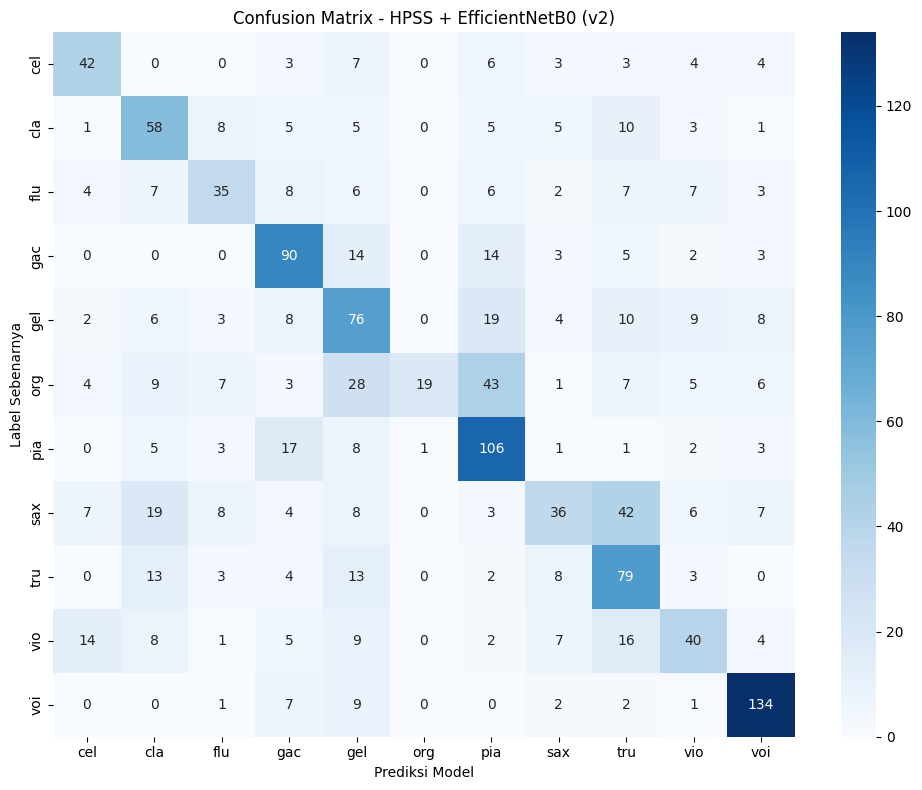

  Model  Akurasi  Precision  Recall  F1_macro
0   CNN   0.5336     0.5636  0.5246    0.5076


In [29]:
# Hasil CNN v2

from sklearn.metrics import precision_score, recall_score

# Ringkasan metrik CNN v2 (format sama dengan yang dibaca app.py)
cnn_results = pd.DataFrame([{
    "Model": "CNN",
    "Akurasi": accuracy_score(y_test, y_pred2),
    "Precision": precision_score(y_test, y_pred2, average="macro", zero_division=0),
    "Recall": recall_score(y_test, y_pred2, average="macro", zero_division=0),
    "F1_macro": f1_score(y_test, y_pred2, average="macro")
}])
cnn_results.to_csv("cnn_results.csv", index=False)

# Classification report per kelas
rep = classification_report(y_test, y_pred2, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
pd.DataFrame(rep).T.to_csv("cnn_classification_report.csv")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred2)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix - HPSS + EfficientNetB0 (v2)")
plt.xlabel("Prediksi Model"); plt.ylabel("Label Sebenarnya")
plt.tight_layout()
plt.savefig("cnn_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

print(cnn_results.round(4))

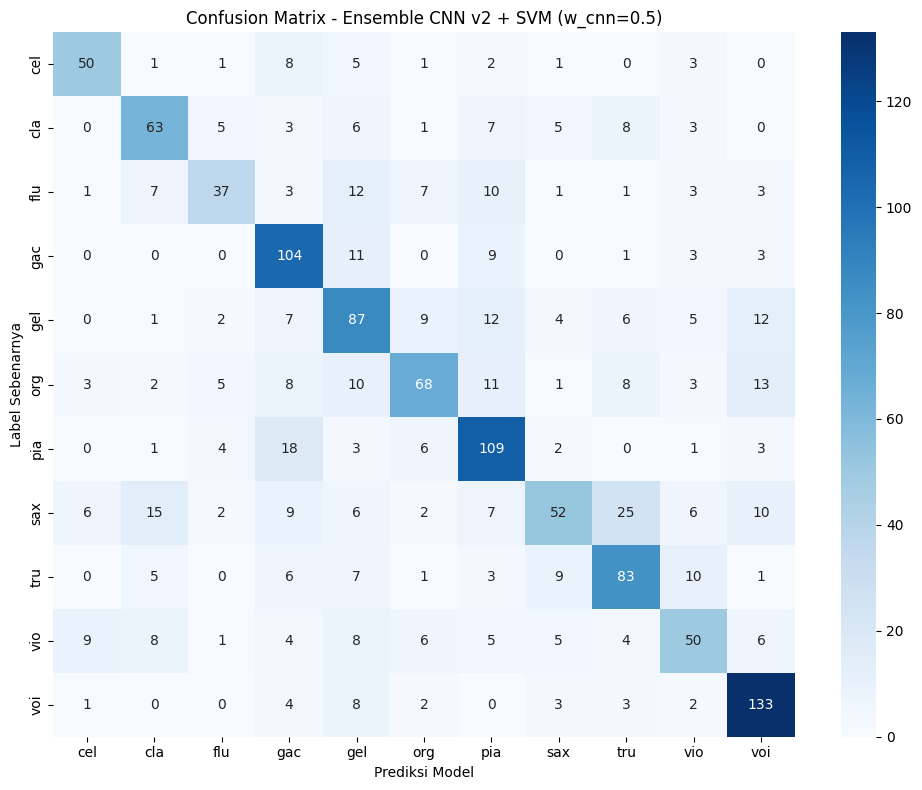

In [30]:
# Hasil ensemble
pred_ens = p_ens.argmax(1)

rep_ens = classification_report(y_test, pred_ens, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
pd.DataFrame(rep_ens).T.to_csv("ensemble_classification_report.csv")

cm_ens = confusion_matrix(y_test, pred_ens)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_ens, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"Confusion Matrix - Ensemble CNN v2 + SVM (w_cnn={best_w:.1f})")
plt.xlabel("Prediksi Model"); plt.ylabel("Label Sebenarnya")
plt.tight_layout()
plt.savefig("ensemble_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

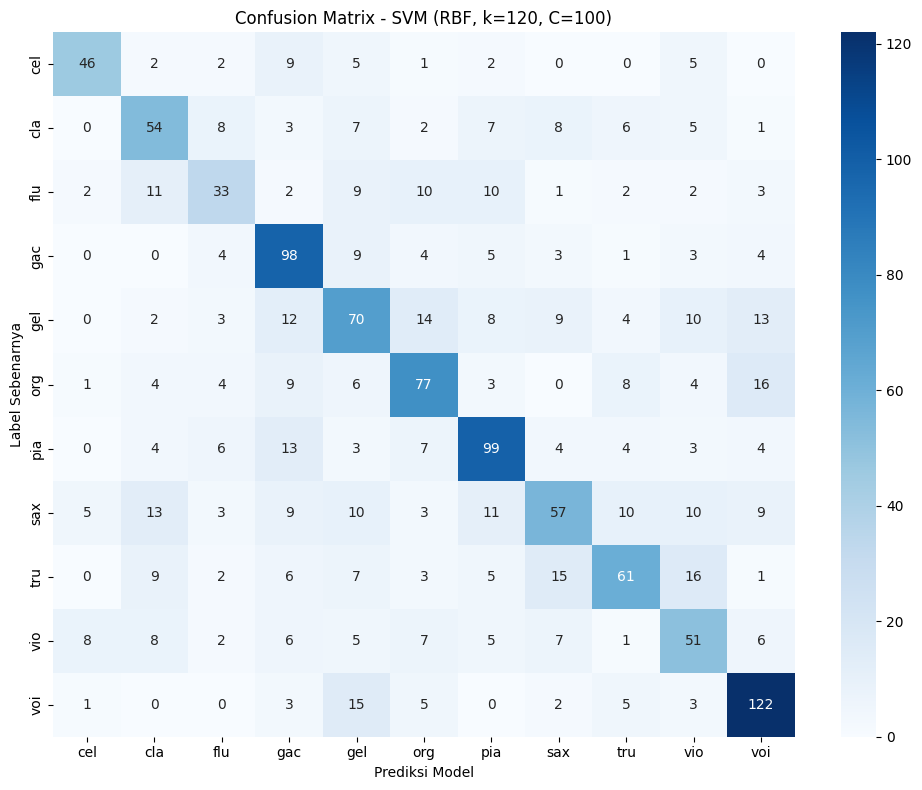

In [36]:
pred_svm = p_svm_test.argmax(1)

cm_svm = confusion_matrix(y_test, pred_svm)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix - SVM (RBF, k=120, C=100)")
plt.xlabel("Prediksi Model"); plt.ylabel("Label Sebenarnya")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

In [40]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

def metrik(y_true, y_pred):
    return {
        "Akurasi":   accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1_macro":  f1_score(y_true, y_pred, average="macro"),
    }

klasik = {
    "Naive Bayes":   GaussianNB(),
    "KNN (k=5)":     KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}

hasil_klasik = {}
for nama, clf in klasik.items():
    pipe = make_pipeline(SelectKBest(f_classif, k=120), StandardScaler(), clf)
    pipe.fit(F_train, y_train)
    hasil_klasik[nama] = metrik(y_test, pipe.predict(F_test))
    print(nama, {k: round(v, 4) for k, v in hasil_klasik[nama].items()})

Naive Bayes {'Akurasi': 0.3515, 'Precision': 0.387, 'Recall': 0.3653, 'F1_macro': 0.3389}
KNN (k=5) {'Akurasi': 0.4313, 'Precision': 0.4256, 'Recall': 0.4285, 'F1_macro': 0.4139}
Decision Tree {'Akurasi': 0.3134, 'Precision': 0.305, 'Recall': 0.307, 'F1_macro': 0.305}
Random Forest {'Akurasi': 0.4925, 'Precision': 0.5165, 'Recall': 0.4865, 'F1_macro': 0.4812}


In [41]:
hasil_test = pd.DataFrame({
    **hasil_klasik,
    "CNN v1 (baseline)": metrik(y_test, y_pred),
    "CNN v2":            metrik(y_test, y_pred2),
    "SVM":               metrik(y_test, p_svm_test.argmax(1)),
    f"Ensemble (w_cnn={best_w:.1f})": metrik(y_test, pred_ens),
}).T[["Akurasi", "Precision", "Recall", "F1_macro"]].round(4)

hasil_test.index.name = "Model"
hasil_test.to_csv("hasil_evaluasi_test.csv")
print(hasil_test)

                      Akurasi  Precision  Recall  F1_macro
Model                                                     
Naive Bayes            0.3515     0.3870  0.3653    0.3389
KNN (k=5)              0.4313     0.4256  0.4285    0.4139
Decision Tree          0.3134     0.3050  0.3070    0.3050
Random Forest          0.4925     0.5165  0.4865    0.4812
CNN v1 (baseline)      0.5448     0.5553  0.5376    0.5277
CNN v2                 0.5336     0.5636  0.5246    0.5076
SVM                    0.5731     0.5703  0.5643    0.5637
Ensemble (w_cnn=0.5)   0.6239     0.6271  0.6149    0.6124


In [38]:
# file untuk folder project
from google.colab import files

# Mengunduh semua file
for f in ["cnn_results.csv", "cnn_classification_report.csv", "cnn_confusion_matrix.png",
          "best_irmas_hpss_efficientnet_v2.keras", "cnn_hpss_preprocessing.joblib",
          "svm_calibrated.joblib", "ensemble_config.joblib",
          "ensemble_classification_report.csv", "ensemble_confusion_matrix.png",
          "hasil_evaluasi_test.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (10 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>